In [1]:
# =====================================================================
# 0.1  Installs, imports, CONFIG
# =====================================================================
import os, sys, subprocess, json, random, shutil, hashlib, time, platform, datetime, zipfile
from pathlib import Path

def pip_install(*pkgs):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=True)

try:
    import ultralytics
except ImportError:
    pip_install("ultralytics")
    import ultralytics

import numpy as np, pandas as pd, cv2, torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display, Image, FileLink, Markdown
from ultralytics import YOLO

# ------------------------------- CONFIG -------------------------------
SEED              = 42
CLASSES           = ["Cattle", "Goat", "Sheep"]      # class id = position in this list
N_IMAGES          = 1500                             # images taken from Open Images V7 (train split)
SPLIT             = dict(train=0.70, val=0.15, test=0.15)
BASE_WEIGHTS      = "yolov8n.pt"                     # COCO-pretrained YOLOv8-nano
EPOCHS, IMGSZ, BATCH, PATIENCE = 50, 640, 16, 10
CONF_COUNT        = 0.25                             # confidence threshold used for counting
IOU_NMS           = 0.7                              # NMS IoU threshold at inference
GROUP_AREA_THRESH = 0.40                             # box >= 40% of the image => flagged as POSSIBLE group box
TINY_AREA         = 0.0005                           # box < 0.05% of the image => flagged as tiny
RETRAIN           = True                             # False = reuse an existing best.pt if one is found
ZIP_DATASET       = False                            # True = also zip the prepared dataset (large file)
# ----------------------------------------------------------------------

WORK     = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path.cwd() / "working"
RAW_DIR  = WORK / "livestock_raw"        # data as downloaded (YOLO format)
DATA_DIR = WORK / "livestock_dataset"    # cleaned + split data used by ALL experiments
RUNS_DIR = WORK / "runs"                 # training / validation runs
OUT_DIR  = WORK / "outputs"              # everything that goes into the report / zip
FIG_DIR, TAB_DIR, PRED_DIR = OUT_DIR / "figures", OUT_DIR / "tables", OUT_DIR / "sample_predictions"
for d in (FIG_DIR, TAB_DIR, PRED_DIR, RUNS_DIR):
    d.mkdir(parents=True, exist_ok=True)

DEVICE = 0 if torch.cuda.is_available() else "cpu"
IMG_EXT = {".jpg", ".jpeg", ".png"}
CLASS_COLORS = ["#2e8b57", "#ff8c00", "#3c6fd6"]      # Cattle, Goat, Sheep (matplotlib)
BOX_BGR = {0: (87, 139, 46), 1: (0, 140, 255), 2: (214, 111, 60)}   # same colours for OpenCV (BGR)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)

try:                       # keep Ultralytics quiet and offline-friendly
    from ultralytics import settings
    settings.update({"wandb": False, "raytune": False})
except Exception:
    pass

RESULTS = {}               # numbers collected along the way, used to auto-write the README
print(f"Python {platform.python_version()} | torch {torch.__version__} | ultralytics {ultralytics.__version__}")
print("Device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU (training will be slow!)")
print("Working folder:", WORK)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Python 3.13.16 | torch 2.11.0+cu130 | ultralytics 8.4.205
Device: Tesla T4
Working folder: /kaggle/working


In [2]:
# =====================================================================
# 0.2  Helper functions (used throughout the notebook)
# =====================================================================
def parse_label_file(path):
    """Read a YOLO label file. Returns (valid_boxes, n_invalid_lines).
    A box is (class_id, x_center, y_center, width, height), all normalised to 0-1."""
    boxes, bad, tol = [], 0, 1e-6
    path = Path(path)
    if not path.exists():
        return boxes, 0
    for line in path.read_text().splitlines():
        p = line.split()
        if not p:
            continue
        try:
            assert len(p) == 5
            c = int(float(p[0])); xc, yc, w, h = map(float, p[1:])
            assert 0 <= c < len(CLASSES)
            assert -tol <= xc <= 1 + tol and -tol <= yc <= 1 + tol and 0 < w <= 1 + tol and 0 < h <= 1 + tol
            boxes.append((c, xc, yc, w, h))
        except Exception:
            bad += 1
    return boxes, bad

def draw_boxes(img_bgr, boxes):
    """Draw YOLO-format ground-truth boxes on a BGR image."""
    h, w = img_bgr.shape[:2]
    out, t = img_bgr.copy(), max(2, int(round(min(h, w) / 250)))
    for c, xc, yc, bw, bh in boxes:
        x1, y1 = int((xc - bw / 2) * w), int((yc - bh / 2) * h)
        x2, y2 = int((xc + bw / 2) * w), int((yc + bh / 2) * h)
        cv2.rectangle(out, (x1, y1), (x2, y2), BOX_BGR[c], t)
        cv2.putText(out, CLASSES[c], (x1 + 2, max(y1 - 5, 14)), cv2.FONT_HERSHEY_SIMPLEX,
                    max(0.5, min(h, w) / 900), BOX_BGR[c], max(1, t - 1), cv2.LINE_AA)
    return out

def rgb(img_bgr):
    return cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

def savefig(name):
    """Save the current matplotlib figure into outputs/figures and show it."""
    plt.tight_layout()
    plt.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    plt.show()

def list_images(folder):
    return sorted(p for p in Path(folder).rglob("*") if p.suffix.lower() in IMG_EXT)

def md_table(df, floatfmt="{:.3f}"):
    """Small DataFrame -> markdown table (used in the README)."""
    cols = list(df.columns)
    lines = ["| " + " | ".join(map(str, cols)) + " |", "|" + "---|" * len(cols)]
    for _, r in df.iterrows():
        lines.append("| " + " | ".join(floatfmt.format(v) if isinstance(v, (float, np.floating)) else str(v) for v in r) + " |")
    return "\n".join(lines)

In [3]:
# =====================================================================
# A1.  Acquire the data (reuse if present, otherwise download with FiftyOne)
# =====================================================================
def find_yolo_roots(base):
    """Folders under `base` that contain both images/ and labels/ (YOLO layout)."""
    hits = []
    for root, dirs, _ in os.walk(base):
        if "images" in dirs and "labels" in dirs:
            hits.append(Path(root)); dirs[:] = []
    return hits

if RAW_DIR.exists() and list_images(RAW_DIR / "images"):
    RAW_SRC = RAW_DIR
    print("Reusing raw data already in", RAW_SRC)
else:
    cands = find_yolo_roots("/kaggle/input") if Path("/kaggle/input").exists() else []
    cands = sorted(cands, key=lambda p: ("livestock_yolo" not in p.name, str(p)))
    if cands:
        RAW_SRC = cands[0]
        print("Reusing data attached to this notebook:", RAW_SRC)
    else:
        print("No local data found: downloading from Open Images V7 (needs Internet = On)...")
        pip_install("fiftyone")
        import fiftyone as fo, fiftyone.zoo as foz
        ds = foz.load_zoo_dataset("open-images-v7", split="train", label_types=["detections"],
                                  classes=CLASSES, max_samples=N_IMAGES, shuffle=True, seed=SEED)
        ds.export(export_dir=str(RAW_DIR), dataset_type=fo.types.YOLOv5Dataset,
                  label_field="ground_truth", classes=CLASSES, split="train")
        RAW_SRC = RAW_DIR

raw_imgs = list_images(RAW_SRC / "images")
print(f"Raw images found: {len(raw_imgs)}")
RESULTS["raw_source"] = str(RAW_SRC)
RESULTS["n_raw"] = len(raw_imgs)

No local data found: downloading from Open Images V7 (needs Internet = On)...


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
/usr/local/lib/python3.13/dist-packages/glob2/fnmatch.py:141: SyntaxWarning: invalid escape sequence '\Z'
  return '(?ms)' + res + '\Z'


 100% |██████|    4.8Gb/4.8Gb [2.5s elapsed, 0s remaining, 2.5Gb/s]         
 100% |█████████████████| 1500/1500 [53.5s elapsed, 0s remaining, 29.5 files/s]      
Dataset info written to '/root/fiftyone/open-images-v7/info.json'
Loading 'open-images-v7' split 'train'
 100% |███████████████| 1500/1500 [12.0s elapsed, 0s remaining, 128.8 samples/s]      
Dataset 'open-images-v7-train-1500' created


/usr/local/lib/python3.13/dist-packages/fiftyone/utils/yolo.py:1154: UserWarning: Ignoring object with label 'Plant' not in provided classes
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/fiftyone/utils/yolo.py:1154: UserWarning: Ignoring object with label 'Woman' not in provided classes
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/fiftyone/utils/yolo.py:1154: UserWarning: Ignoring object with label 'Clothing' not in provided classes
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/fiftyone/utils/yolo.py:1154: UserWarning: Ignoring object with label 'Picture frame' not in provided classes
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/fiftyone/utils/yolo.py:1154: UserWarning: Ignoring object with label 'Tree' not in provided classes
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/fiftyone/utils/yolo.py:1154: UserWarning: Ignoring object with label 'Person' not in provided classes
  warnings.warn(msg)
/usr/local/lib/py

   6% ||--------------|   96/1500 [431.0ms elapsed, 6.3s remaining, 222.7 samples/s] 

/usr/local/lib/python3.13/dist-packages/fiftyone/utils/yolo.py:1154: UserWarning: Ignoring object with label 'Poster' not in provided classes
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/fiftyone/utils/yolo.py:1154: UserWarning: Ignoring object with label 'Bathtub' not in provided classes
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/fiftyone/utils/yolo.py:1154: UserWarning: Ignoring object with label 'Furniture' not in provided classes
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/fiftyone/utils/yolo.py:1154: UserWarning: Ignoring object with label 'Bronze sculpture' not in provided classes
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/fiftyone/utils/yolo.py:1154: UserWarning: Ignoring object with label 'Jeans' not in provided classes
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/fiftyone/utils/yolo.py:1154: UserWarning: Ignoring object with label 'Horse' not in provided classes
  warnings.warn(msg)
/usr/local

... (35 outputs left out)

/usr/local/lib/python3.13/dist-packages/fiftyone/utils/yolo.py:1154: UserWarning: Ignoring object with label 'Bicycle wheel' not in provided classes
  warnings.warn(msg)


  94% |██████████████\| 1417/1500 [5.7s elapsed, 323.6ms remaining, 256.9 samples/s] 

/usr/local/lib/python3.13/dist-packages/fiftyone/utils/yolo.py:1154: UserWarning: Ignoring object with label 'Boat' not in provided classes
  warnings.warn(msg)


 100% |███████████████| 1500/1500 [6.0s elapsed, 0s remaining, 261.4 samples/s]      
Raw images found: 1500


In [4]:
# =====================================================================
# A2.  Quality audit of every image + label file
# =====================================================================
rows, labels_clean, seen_names = [], {}, set()
for p in tqdm(raw_imgs, desc="Auditing"):
    rel = p.relative_to(RAW_SRC / "images")
    lbl = (RAW_SRC / "labels" / rel).with_suffix(".txt")
    img = cv2.imread(str(p))
    boxes, bad = parse_label_file(lbl)
    areas = [b[3] * b[4] for b in boxes]
    rows.append(dict(
        image=p.name, path=str(p), readable=img is not None,
        width=img.shape[1] if img is not None else 0, height=img.shape[0] if img is not None else 0,
        label_exists=lbl.exists(), n_boxes=len(boxes), n_invalid_lines=bad,
        n_tiny=int(sum(a < TINY_AREA for a in areas)),
        n_possible_group=int(sum(a >= GROUP_AREA_THRESH for a in areas)),
        dup_name=p.name in seen_names, md5=hashlib.md5(p.read_bytes()).hexdigest()))
    seen_names.add(p.name)
    labels_clean[p.name] = boxes

qc = pd.DataFrame(rows)
qc["dup_content"] = qc.duplicated("md5", keep="first")
qc["keep"] = qc.readable & (qc.n_boxes > 0) & ~qc.dup_name & ~qc.dup_content
qc.drop(columns="path").to_csv(TAB_DIR / "quality_audit_per_image.csv", index=False)

audit = pd.DataFrame({
    "Check": ["Images audited", "Unreadable images", "Images with no label file", "Images with no valid boxes",
              "Malformed / out-of-range label lines (dropped)", "Duplicate file names", "Duplicate images (same hash)",
              "Images containing tiny boxes (<0.05% of image)", "Images containing a possible group box (area >= 40%)",
              "IMAGES KEPT"],
    "Count": [len(qc), int((~qc.readable).sum()), int((~qc.label_exists).sum()), int((qc.n_boxes == 0).sum()),
              int(qc.n_invalid_lines.sum()), int(qc.dup_name.sum()), int(qc.dup_content.sum()),
              int((qc.n_tiny > 0).sum()), int((qc.n_possible_group > 0).sum()), int(qc.keep.sum())]})
audit.to_csv(TAB_DIR / "quality_audit_summary.csv", index=False)
display(audit)
print(f"Image size (pixels): width min/median/max = {qc.width.min()}/{int(qc.width.median())}/{qc.width.max()}, "
      f"height min/median/max = {qc.height.min()}/{int(qc.height.median())}/{qc.height.max()}")
RESULTS["audit"] = dict(zip(audit.Check, audit.Count.astype(int)))

Auditing:   0%|          | 0/1500 [00:00<?, ?it/s]

,Check,Count
0,Images audited,1500
1,Unreadable images,0
2,Images with no label file,0
3,Images with no valid boxes,0
4,Malformed / out-of-range label lines (dropped),0
5,Duplicate file names,0
6,Duplicate images (same hash),0
7,Images containing tiny boxes (<0.05% of image),46
8,Images containing a possible group box (area >...,447
9,IMAGES KEPT,1500


Image size (pixels): width min/median/max = 492/1024/1024, height min/median/max = 283/767/1024


In [5]:
# =====================================================================
# A3.  Stratified split, leakage check, write the final dataset + data.yaml
# =====================================================================
from sklearn.model_selection import train_test_split

keep = qc[qc.keep].reset_index(drop=True)
keep["stratum"] = keep.image.map(lambda n: int(np.bincount([b[0] for b in labels_clean[n]], minlength=len(CLASSES)).argmax()))

idx = np.arange(len(keep))
hold = SPLIT["val"] + SPLIT["test"]
try:
    tr, tmp = train_test_split(idx, test_size=hold, random_state=SEED, stratify=keep.stratum)
    va, te = train_test_split(tmp, test_size=SPLIT["test"] / hold, random_state=SEED, stratify=keep.stratum.iloc[tmp])
    print("Stratified split used.")
except ValueError as e:          # a class too rare to stratify
    print("Stratification failed (", e, ") -> plain random split.")
    rng = np.random.RandomState(SEED); rng.shuffle(idx)
    n1, n2 = int(len(idx) * SPLIT["train"]), int(len(idx) * (SPLIT["train"] + SPLIT["val"]))
    tr, va, te = idx[:n1], idx[n1:n2], idx[n2:]
split_idx = dict(train=tr, val=va, test=te)

# ---- leakage check: no file name or file content shared between splits ----
names = {s: set(keep.image.iloc[i]) for s, i in split_idx.items()}
hashes = {s: set(keep.md5.iloc[i]) for s, i in split_idx.items()}
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    assert not (names[a] & names[b]), f"File-name leakage between {a} and {b}"
    assert not (hashes[a] & hashes[b]), f"Content leakage between {a} and {b}"
print("Leakage check passed: no shared file names or file hashes between train / val / test.")

# ---- write the dataset ----
if DATA_DIR.exists():
    shutil.rmtree(DATA_DIR)
(OUT_DIR / "splits").mkdir(exist_ok=True)
for s, ii in split_idx.items():
    (DATA_DIR / "images" / s).mkdir(parents=True); (DATA_DIR / "labels" / s).mkdir(parents=True)
    for _, r in keep.iloc[ii].iterrows():
        shutil.copy2(r.path, DATA_DIR / "images" / s / r.image)
        lines = [f"{c} {x:.6f} {y:.6f} {w:.6f} {h:.6f}" for c, x, y, w, h in labels_clean[r.image]]
        (DATA_DIR / "labels" / s / (Path(r.image).stem + ".txt")).write_text("\n".join(lines) + "\n")
    (OUT_DIR / "splits" / f"{s}.txt").write_text("\n".join(sorted(keep.image.iloc[ii])) + "\n")

DATA_YAML = DATA_DIR / "data.yaml"
DATA_YAML.write_text(f"path: {DATA_DIR}\ntrain: images/train\nval: images/val\ntest: images/test\n"
                     "names:\n" + "".join(f"  {i}: {c}\n" for i, c in enumerate(CLASSES)))
shutil.copy2(DATA_YAML, OUT_DIR / "data.yaml")
print(DATA_YAML.read_text())

Stratified split used.
Leakage check passed: no shared file names or file hashes between train / val / test.
path: /kaggle/working/livestock_dataset
train: images/train
val: images/val
test: images/test
names:
  0: Cattle
  1: Goat
  2: Sheep



### A4. Dataset statistics (final, cleaned dataset)

,Split,Images,Boxes,Cattle boxes,Goat boxes,Sheep boxes,Boxes/image
0,train,1050,3788,2561,497,730,3.61
1,val,225,819,518,86,215,3.64
2,test,225,830,574,100,156,3.69
3,TOTAL,1500,5437,3653,683,1101,3.62


Box size distribution (% of boxes): {'medium (1-10%)': 38.6, 'small (<1%)': 32.6, 'large (>10%)': 28.9}
Median box area = 2.882% of the image | boxes >= 40% of image: 486 (8.9%)


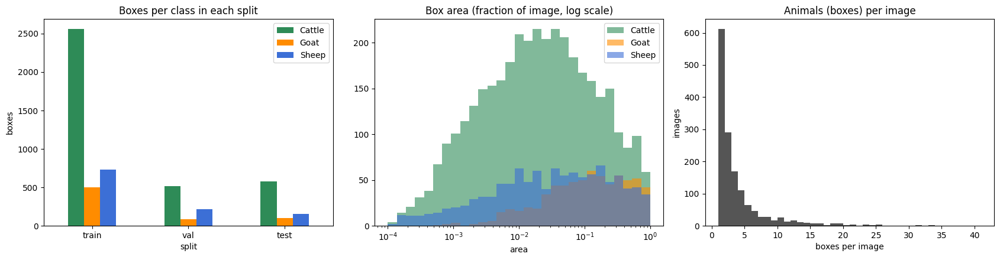

In [6]:
# =====================================================================
# A4.  Statistics of the final dataset + figures
# =====================================================================
brow = []
for s in SPLIT:
    for f in list_images(DATA_DIR / "images" / s):
        h_w = qc.loc[qc.image == f.name, ["width", "height"]].iloc[0]
        for c, xc, yc, w, h in parse_label_file(DATA_DIR / "labels" / s / (f.stem + ".txt"))[0]:
            brow.append(dict(split=s, image=f.name, cls=c, w=w, h=h, area=w * h))
boxes_df = pd.DataFrame(brow)
boxes_df["size"] = pd.cut(boxes_df.area, [0, 0.01, 0.10, 1.01], labels=["small (<1%)", "medium (1-10%)", "large (>10%)"])
boxes_df.to_csv(TAB_DIR / "all_boxes.csv", index=False)

# --- table: images and boxes per split and class ---
summ = []
for s in SPLIT:
    b = boxes_df[boxes_df.split == s]
    summ.append({"Split": s, "Images": b.image.nunique(), "Boxes": len(b),
                 **{f"{c} boxes": int((b.cls == i).sum()) for i, c in enumerate(CLASSES)},
                 "Boxes/image": round(len(b) / b.image.nunique(), 2)})
tot = boxes_df
summ.append({"Split": "TOTAL", "Images": tot.image.nunique(), "Boxes": len(tot),
             **{f"{c} boxes": int((tot.cls == i).sum()) for i, c in enumerate(CLASSES)},
             "Boxes/image": round(len(tot) / tot.image.nunique(), 2)})
summ = pd.DataFrame(summ); display(summ); summ.to_csv(TAB_DIR / "dataset_summary.csv", index=False)
RESULTS["dataset_summary"] = summ

sz = boxes_df["size"].value_counts(normalize=True).mul(100).round(1)
print("Box size distribution (% of boxes):", sz.to_dict())
print(f"Median box area = {boxes_df.area.median():.3%} of the image | boxes >= {GROUP_AREA_THRESH:.0%} of image: "
      f"{(boxes_df.area >= GROUP_AREA_THRESH).sum()} ({(boxes_df.area >= GROUP_AREA_THRESH).mean():.1%})")
RESULTS["box_size_pct"] = sz.to_dict()

# --- figure: class distribution / box size / boxes per image ---
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ct = boxes_df.groupby(["split", "cls"]).size().unstack(fill_value=0).reindex(list(SPLIT))
ct.columns = CLASSES
ct.plot.bar(ax=ax[0], color=CLASS_COLORS, rot=0); ax[0].set_title("Boxes per class in each split"); ax[0].set_ylabel("boxes")
for i, c in enumerate(CLASSES):
    ax[1].hist(boxes_df[boxes_df.cls == i].area, bins=np.logspace(-4, 0, 30), alpha=.6, color=CLASS_COLORS[i], label=c)
ax[1].set_xscale("log"); ax[1].set_title("Box area (fraction of image, log scale)"); ax[1].set_xlabel("area"); ax[1].legend()
per_img = boxes_df.groupby("image").size()
ax[2].hist(per_img, bins=range(1, int(min(per_img.max(), 40)) + 2), color="#555"); ax[2].set_title("Animals (boxes) per image")
ax[2].set_xlabel("boxes per image"); ax[2].set_ylabel("images")
savefig("fig_A_dataset_statistics.png")
RESULTS["boxes_per_image_mean"] = float(per_img.mean())

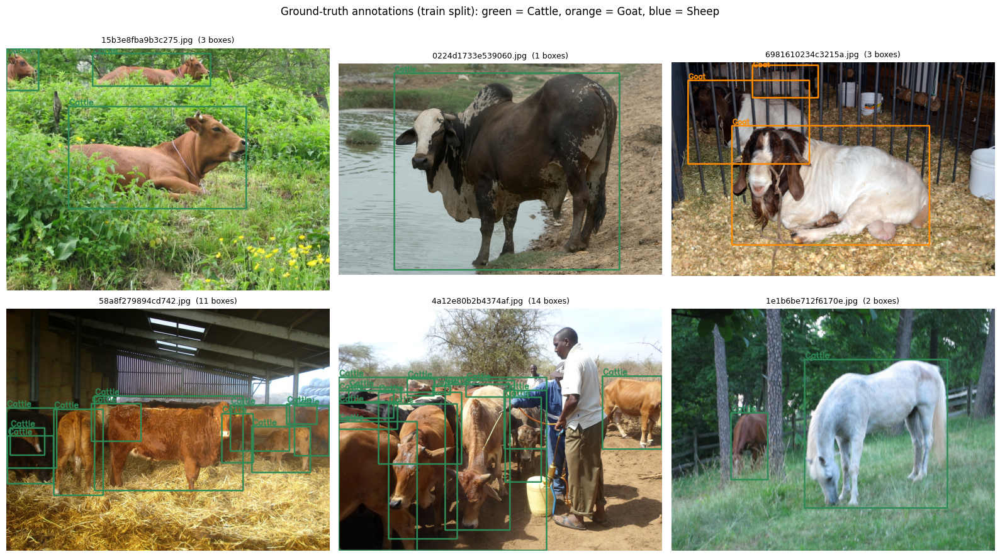

In [7]:
# =====================================================================
# A4b.  Sample ground-truth images from the training split
# =====================================================================
rng = random.Random(SEED)
sample = rng.sample(list_images(DATA_DIR / "images" / "train"), 6)
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, f in zip(axes.ravel(), sample):
    boxes, _ = parse_label_file(DATA_DIR / "labels" / "train" / (f.stem + ".txt"))
    ax.imshow(rgb(draw_boxes(cv2.imread(str(f)), boxes))); ax.set_title(f"{f.name}  ({len(boxes)} boxes)", fontsize=9); ax.axis("off")
plt.suptitle("Ground-truth annotations (train split): green = Cattle, orange = Goat, blue = Sheep", y=1.0)
savefig("fig_A_sample_ground_truth.png")

In [8]:
# =====================================================================
# B6.  Record software + hardware + configuration (for reproducibility)
# =====================================================================
env = {
    "date": datetime.datetime.now().isoformat(timespec="seconds"),
    "python": platform.python_version(), "platform": platform.platform(),
    "torch": torch.__version__, "cuda": torch.version.cuda,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (CPU)",
    "ultralytics": ultralytics.__version__, "numpy": np.__version__, "pandas": pd.__version__, "opencv": cv2.__version__,
}
config = dict(SEED=SEED, CLASSES=CLASSES, N_IMAGES=N_IMAGES, SPLIT=SPLIT, BASE_WEIGHTS=BASE_WEIGHTS, EPOCHS=EPOCHS,
              IMGSZ=IMGSZ, BATCH=BATCH, PATIENCE=PATIENCE, CONF_COUNT=CONF_COUNT, IOU_NMS=IOU_NMS,
              GROUP_AREA_THRESH=GROUP_AREA_THRESH, TINY_AREA=TINY_AREA)
(OUT_DIR / "env.json").write_text(json.dumps(env, indent=2))
(OUT_DIR / "config.json").write_text(json.dumps(config, indent=2))
(OUT_DIR / "requirements.txt").write_text(
    f"ultralytics=={env['ultralytics']}\ntorch=={env['torch']}\nnumpy=={env['numpy']}\npandas=={env['pandas']}\n"
    f"opencv-python=={env['opencv']}\nmatplotlib\nscikit-learn\ntqdm\nfiftyone  # only needed to download the data\n")
RESULTS["env"] = env; RESULTS["config"] = config
display(pd.DataFrame({"Item": list(env), "Value": list(env.values())}))

,Item,Value
0,date,2026-11-07T17:11:17
1,python,3.13.16
2,platform,Linux-6.18.55+-x86_64-with-glibc2.39
3,torch,2.11.0+cu130
4,cuda,13.0
5,gpu,Tesla T4
6,ultralytics,8.4.205
7,numpy,2.1.3
8,pandas,2.3.3
9,opencv,4.14.0


In [9]:
# =====================================================================
# C1.  Train YOLOv8n
# =====================================================================
RUN_NAME = "baseline_yolov8n"
BEST = RUNS_DIR / RUN_NAME / "weights" / "best.pt"

if RETRAIN or not BEST.exists():
    set_seed(SEED)
    t0 = time.time()
    model = YOLO(BASE_WEIGHTS)
    model.train(data=str(DATA_YAML), epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH, patience=PATIENCE, seed=SEED,
                project=str(RUNS_DIR), name=RUN_NAME, exist_ok=True, device=DEVICE, workers=2, plots=True)
    RESULTS["train_minutes"] = round((time.time() - t0) / 60, 1)
    BEST = Path(model.trainer.best)
else:
    print("Reusing existing weights:", BEST)
model = YOLO(str(BEST))          # always evaluate the BEST checkpoint
print("Best weights:", BEST)

Ultralytics 8.4.205 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/livestock_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=baseline_yolov8n, nbs=64, nms=None, opset=None

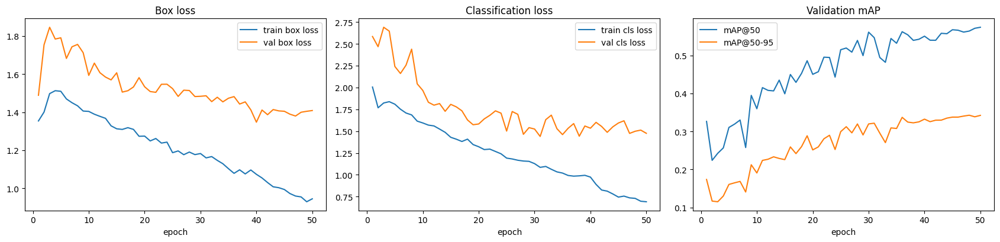

Epochs run: 50 | best epoch (val mAP@50-95): 48


In [10]:
# =====================================================================
# C1b.  Training curves (from results.csv written by Ultralytics)
# =====================================================================
csv = BEST.parent.parent / "results.csv"
if csv.exists():
    hist = pd.read_csv(csv); hist.columns = hist.columns.str.strip()
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
    ax[0].plot(hist["epoch"], hist["train/box_loss"], label="train box loss"); ax[0].plot(hist["epoch"], hist["val/box_loss"], label="val box loss")
    ax[0].set_title("Box loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(hist["epoch"], hist["train/cls_loss"], label="train cls loss"); ax[1].plot(hist["epoch"], hist["val/cls_loss"], label="val cls loss")
    ax[1].set_title("Classification loss"); ax[1].set_xlabel("epoch"); ax[1].legend()
    ax[2].plot(hist["epoch"], hist["metrics/mAP50(B)"], label="mAP@50"); ax[2].plot(hist["epoch"], hist["metrics/mAP50-95(B)"], label="mAP@50-95")
    ax[2].set_title("Validation mAP"); ax[2].set_xlabel("epoch"); ax[2].legend()
    savefig("fig_C_training_curves.png")
    best_ep = int(hist.loc[hist["metrics/mAP50-95(B)"].idxmax(), "epoch"])
    print(f"Epochs run: {len(hist)} | best epoch (val mAP@50-95): {best_ep}")
    RESULTS["epochs_run"] = len(hist); RESULTS["best_epoch"] = best_ep
    shutil.copy2(csv, OUT_DIR / "tables" / "training_history.csv")
else:
    print("results.csv not found, skipping the curves.")

Ultralytics 8.4.205 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4029.7±728.1 MB/s, size: 485.9 KB)
val: Scanning /kaggle/working/livestock_dataset/labels/test... 225 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 225/225 1.1Kit/s 0.2s
val: New cache created: /kaggle/working/livestock_dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 5.4it/s 2.8s
                   all        225        830      0.611      0.566      0.586      0.354
Speed: 0.8ms preprocess, 5.1ms inference, 0.0ms loss, 1.4ms postprocess per image
Results saved to /kaggle/working/runs/test_eval


,Class,Test boxes,Precision,Recall,mAP@50,mAP@50-95
0,Cattle,574,0.664,0.593,0.637,0.347
1,Goat,100,0.560,0.585,0.566,0.365
2,Sheep,156,0.607,0.519,0.555,0.350
3,ALL,830,0.611,0.566,0.586,0.354


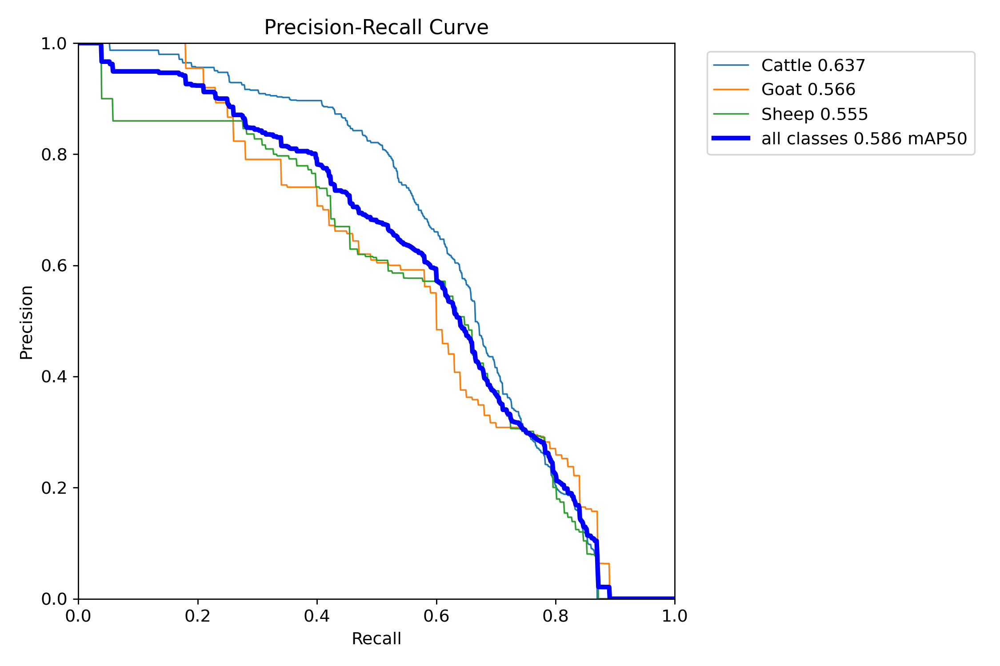

In [11]:
# =====================================================================
# C2.  Detection metrics on the TEST split (per class + overall)
# =====================================================================
vm = model.val(data=str(DATA_YAML), split="test", imgsz=IMGSZ, batch=BATCH, conf=0.001, iou=0.6, plots=True,
               project=str(RUNS_DIR), name="test_eval", exist_ok=True, device=DEVICE, verbose=False)
test_counts = boxes_df[boxes_df.split == "test"].groupby("cls").size()
rows = []
for i, ci in enumerate(vm.box.ap_class_index):
    p, r, ap50, ap = vm.box.class_result(i)
    rows.append({"Class": CLASSES[int(ci)], "Test boxes": int(test_counts.get(int(ci), 0)),
                 "Precision": p, "Recall": r, "mAP@50": ap50, "mAP@50-95": ap})
det = pd.DataFrame(rows)
det.loc[len(det)] = {"Class": "ALL", "Test boxes": int(test_counts.sum()), "Precision": vm.box.mp, "Recall": vm.box.mr,
                     "mAP@50": vm.box.map50, "mAP@50-95": vm.box.map}
det.to_csv(TAB_DIR / "detection_metrics_test.csv", index=False)
display(det.round(3))
RESULTS["det"] = det

# curves produced by Ultralytics (PR curve etc.) -> copy to outputs and show
for pat in ("*PR_curve.png", "*F1_curve.png"):
    for f in Path(vm.save_dir).glob(pat):
        shutil.copy2(f, FIG_DIR / f"fig_C_{f.name}")
for f in sorted(FIG_DIR.glob("fig_C_*PR_curve.png")):
    display(Image(filename=str(f), width=600))

Ultralytics 8.4.205 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2938.9±1001.0 MB/s, size: 175.8 KB)
val: Scanning /kaggle/working/livestock_dataset/labels/test.cache... 225 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 225/225 44.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 5.6it/s 2.7s
                   all        225        830       0.57      0.601      0.497      0.306
Speed: 1.1ms preprocess, 3.9ms inference, 0.0ms loss, 1.0ms postprocess per image
Results saved to /kaggle/working/runs/test_confusion


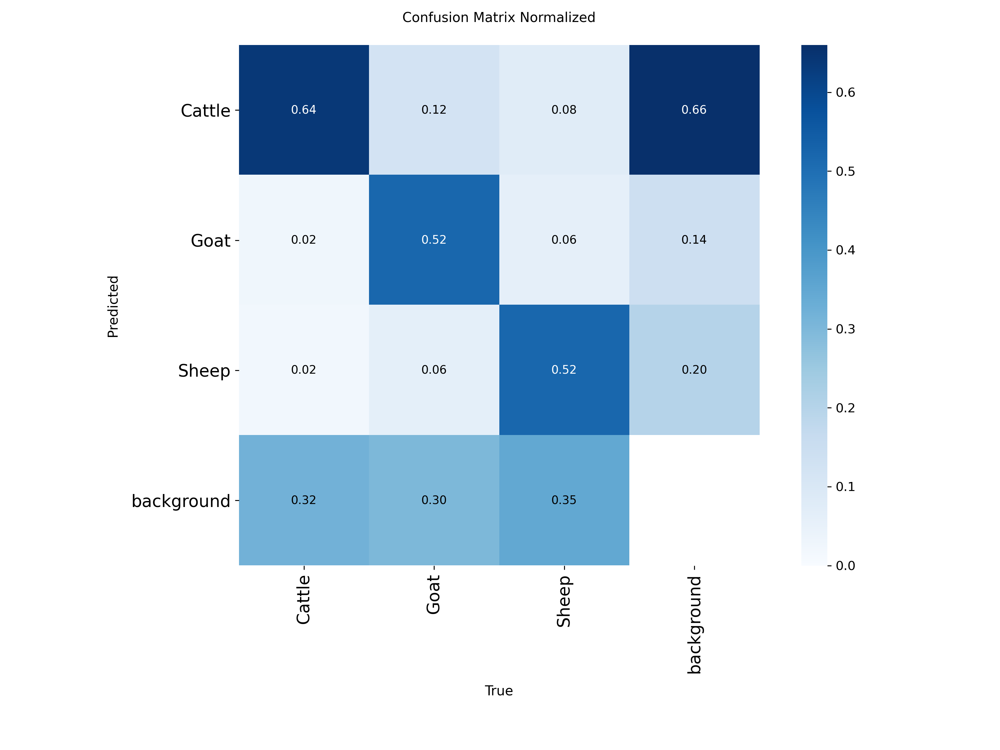

In [12]:
# =====================================================================
# C2b.  Confusion matrix at the counting threshold (CONF_COUNT)
# =====================================================================
cmv = model.val(data=str(DATA_YAML), split="test", imgsz=IMGSZ, batch=BATCH, conf=CONF_COUNT, iou=0.6, plots=True,
                project=str(RUNS_DIR), name="test_confusion", exist_ok=True, device=DEVICE, verbose=False)
cm = np.array(cmv.confusion_matrix.matrix, dtype=float)          # rows = predicted, columns = true (last = background)
labels = CLASSES + ["background"]
cm_norm = cm / cm.sum(axis=0, keepdims=True).clip(min=1)
pd.DataFrame(cm, index=[f"pred {l}" for l in labels], columns=[f"true {l}" for l in labels]).to_csv(TAB_DIR / "confusion_matrix_counts.csv")
for f in Path(cmv.save_dir).glob("confusion_matrix*.png"):
    shutil.copy2(f, FIG_DIR / f"fig_C_{f.name}")
display(Image(filename=str(FIG_DIR / "fig_C_confusion_matrix_normalized.png"), width=650)) if (FIG_DIR / "fig_C_confusion_matrix_normalized.png").exists() else None
RESULTS["cm"] = cm; RESULTS["cm_norm"] = cm_norm

In [13]:
# =====================================================================
# C3.  Counting evaluation (test split) + cached predictions
# =====================================================================
CACHE_CONF = 0.05

def predict_split(split, conf=CACHE_CONF, bs=32):
    """Run the model on every image of a split. Returns {image_name: dict(conf, cls, xyxyn)}."""
    files, out = list_images(DATA_DIR / "images" / split), {}
    for i in tqdm(range(0, len(files), bs), desc=f"Predicting {split}"):
        chunk = files[i:i + bs]
        res = model.predict([str(f) for f in chunk], conf=conf, iou=IOU_NMS, imgsz=IMGSZ, device=DEVICE, verbose=False)
        for f, r in zip(chunk, res):
            out[f.name] = dict(conf=r.boxes.conf.cpu().numpy(), cls=r.boxes.cls.cpu().numpy().astype(int),
                               xyxyn=r.boxes.xyxyn.cpu().numpy())
    return out

def gt_table(split):
    """Ground-truth counts per image (total + per class) and the possible-group-box flag."""
    rows = []
    for f in list_images(DATA_DIR / "images" / split):
        boxes, _ = parse_label_file(DATA_DIR / "labels" / split / (f.stem + ".txt"))
        cnt = np.bincount([b[0] for b in boxes], minlength=len(CLASSES))
        areas = [b[3] * b[4] for b in boxes]
        rows.append(dict(image=f.name, gt_total=len(boxes), **{f"gt_{c}": int(cnt[i]) for i, c in enumerate(CLASSES)},
                         max_box_area=max(areas) if areas else 0.0, group_flag=bool(areas and max(areas) >= GROUP_AREA_THRESH)))
    return pd.DataFrame(rows)

def counts_at(split, preds, thr):
    """Per-image ground truth vs predicted counts when only detections with conf >= thr are kept."""
    df = gt_table(split)
    for i, c in enumerate(CLASSES):
        df[f"pred_{c}"] = [int(((preds[n]["conf"] >= thr) & (preds[n]["cls"] == i)).sum()) for n in df.image]
    df["pred_total"] = df[[f"pred_{c}" for c in CLASSES]].sum(axis=1)
    df["error"] = df.pred_total - df.gt_total
    df["abs_error"] = df.error.abs()
    return df

def count_metrics(df):
    e = df.pred_total - df.gt_total
    return dict(Images=len(df), True_animals=int(df.gt_total.sum()), Predicted_animals=int(df.pred_total.sum()),
                MAE=abs(e).mean(), RMSE=float(np.sqrt((e ** 2).mean())), Bias=e.mean(),
                Mean_rel_error_pct=100 * (abs(e) / df.gt_total.clip(lower=1)).mean(),
                Exact_pct=100 * (e == 0).mean(), Within1_pct=100 * (abs(e) <= 1).mean())

test_preds = predict_split("test")
dft = counts_at("test", test_preds, CONF_COUNT)
dft.to_csv(TAB_DIR / "counting_per_image_test.csv", index=False)

subsets = {"All test images": dft,
           "Images WITHOUT a possible group box": dft[~dft.group_flag],
           "Images WITH a possible group box": dft[dft.group_flag]}
cnt_tab = pd.DataFrame.from_dict({k: count_metrics(v) for k, v in subsets.items() if len(v)}, orient="index")
cnt_tab.to_csv(TAB_DIR / "counting_metrics_test.csv")
display(cnt_tab.round(2))

pc = pd.DataFrame([{"Class": c,
                    "True": int(dft[f"gt_{c}"].sum()), "Predicted": int(dft[f"pred_{c}"].sum()),
                    "MAE": (dft[f"pred_{c}"] - dft[f"gt_{c}"]).abs().mean(), "Bias": (dft[f"pred_{c}"] - dft[f"gt_{c}"]).mean()}
                   for c in CLASSES])
pc.to_csv(TAB_DIR / "counting_per_class_test.csv", index=False)
display(pc.round(2))
RESULTS["cnt_tab"] = cnt_tab; RESULTS["cnt_class"] = pc; RESULTS["count_all"] = count_metrics(dft)

Predicting test:   0%|          | 0/8 [00:00<?, ?it/s]

,Images,True_animals,Predicted_animals,MAE,RMSE,Bias,Mean_rel_error_pct,Exact_pct,Within1_pct
All test images,225,830,839,1.35,2.75,0.04,43.67,45.78,69.33
Images WITHOUT a possible group box,145,678,655,1.52,2.90,-0.16,43.90,40.69,64.83
Images WITH a possible group box,80,152,184,1.02,2.44,0.40,43.25,55.00,77.50


,Class,True,Predicted,MAE,Bias
0,Cattle,574,588,1.17,0.06
1,Goat,100,113,0.34,0.06
2,Sheep,156,138,0.41,-0.08


In [14]:
# =====================================================================
# C4.  Latency, FPS, model size, parameters, GPU memory
# =====================================================================
timing_files = list_images(DATA_DIR / "images" / "test")[:100]
for f in timing_files[:3]:                                   # warm-up (not timed)
    model.predict(str(f), imgsz=IMGSZ, device=DEVICE, verbose=False)
if torch.cuda.is_available():
    torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
speeds, wall = [], []
for f in timing_files:
    t = time.perf_counter()
    r = model.predict(str(f), conf=CONF_COUNT, iou=IOU_NMS, imgsz=IMGSZ, device=DEVICE, verbose=False)[0]
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    wall.append((time.perf_counter() - t) * 1000); speeds.append(r.speed)
sp = pd.DataFrame(speeds).mean()
params = sum(p.numel() for p in model.model.parameters())
perf = {"Images timed": len(timing_files), "Pre-processing (ms)": sp["preprocess"], "Inference (ms)": sp["inference"],
        "Post-processing (ms)": sp["postprocess"], "End-to-end per image (ms)": float(np.mean(wall)),
        "Throughput (images/s)": 1000 / float(np.mean(wall)), "Parameters (million)": params / 1e6,
        "Weights file size (MB)": BEST.stat().st_size / 1e6,
        "Peak GPU memory (MB)": torch.cuda.max_memory_allocated() / 1e6 if torch.cuda.is_available() else float("nan"),
        "Device": env["gpu"]}
perf_df = pd.DataFrame({"Measure": list(perf), "Value": [round(v, 2) if isinstance(v, float) else v for v in perf.values()]})
perf_df.to_csv(TAB_DIR / "speed_and_memory.csv", index=False)
display(perf_df); RESULTS["perf"] = perf

,Measure,Value
0,Images timed,100
1,Pre-processing (ms),1.72
2,Inference (ms),11.87
3,Post-processing (ms),1.22
4,End-to-end per image (ms),22.62
5,Throughput (images/s),44.21
6,Parameters (million),3.14
7,Weights file size (MB),6.48
8,Peak GPU memory (MB),156.4
9,Device,Tesla T4


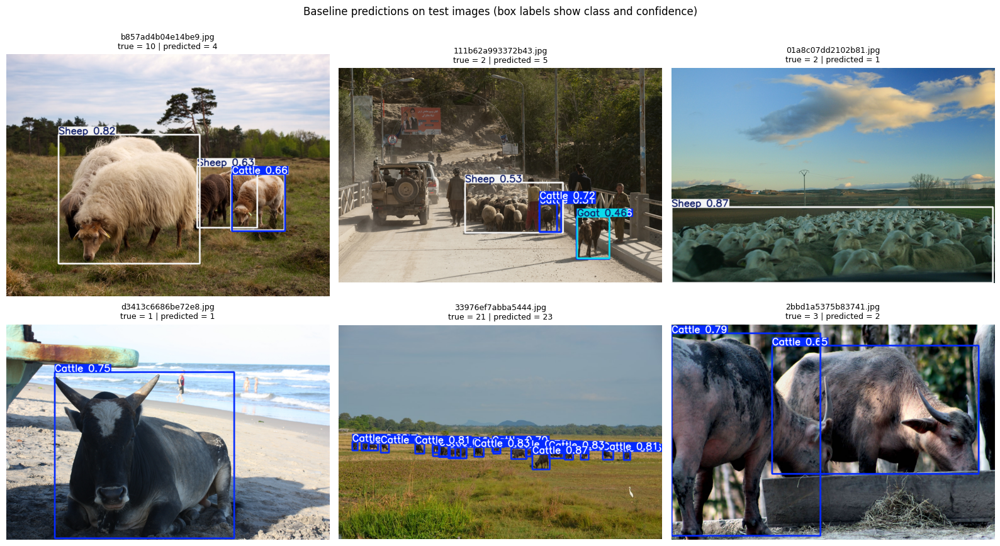

In [15]:
# =====================================================================
# C5.  Sample predictions: saved to outputs/sample_predictions and shown here
# =====================================================================
rng = random.Random(SEED)
test_files = list_images(DATA_DIR / "images" / "test")
picked = rng.sample(test_files, min(12, len(test_files)))
for f in picked:                                             # save 12 annotated images for the report
    r = model.predict(str(f), conf=CONF_COUNT, iou=IOU_NMS, imgsz=IMGSZ, device=DEVICE, verbose=False)[0]
    cv2.imwrite(str(PRED_DIR / f"pred_{f.name}"), r.plot())
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, f in zip(axes.ravel(), picked[:6]):
    r = model.predict(str(f), conf=CONF_COUNT, iou=IOU_NMS, imgsz=IMGSZ, device=DEVICE, verbose=False)[0]
    g = int(dft.loc[dft.image == f.name, "gt_total"].iloc[0])
    ax.imshow(rgb(r.plot())); ax.set_title(f"{f.name}\ntrue = {g} | predicted = {len(r.boxes)}", fontsize=9); ax.axis("off")
plt.suptitle("Baseline predictions on test images (box labels show class and confidence)", y=1.0)
savefig("fig_C_sample_predictions.png")

---
# D. Baseline analysis
### D1. Results overview (tables and graphs)

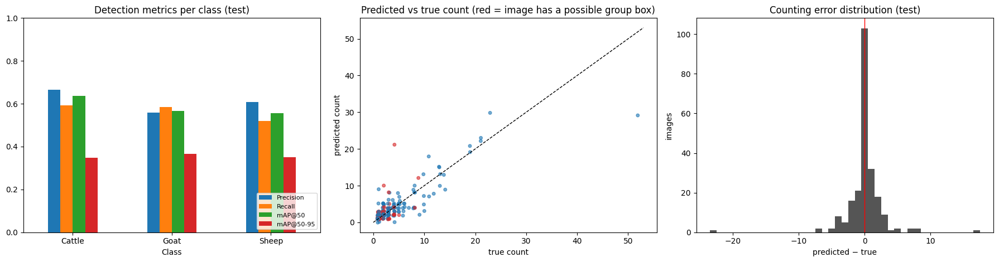

In [16]:
# =====================================================================
# D1.  Per-class detection bar chart + counting scatter + error histogram
# =====================================================================
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
d = det[det.Class != "ALL"].set_index("Class")[["Precision", "Recall", "mAP@50", "mAP@50-95"]]
d.plot.bar(ax=ax[0], rot=0, ylim=(0, 1)); ax[0].set_title("Detection metrics per class (test)"); ax[0].legend(loc="lower right", fontsize=8)

rng_j = np.random.RandomState(SEED)
jit = lambda v: v + rng_j.uniform(-.2, .2, len(v))
colr = np.where(dft.group_flag, "#d62728", "#1f77b4")
ax[1].scatter(jit(dft.gt_total), jit(dft.pred_total), c=colr, s=16, alpha=.6)
m = max(dft.gt_total.max(), dft.pred_total.max()) + 1
ax[1].plot([0, m], [0, m], "k--", lw=1); ax[1].set_xlabel("true count"); ax[1].set_ylabel("predicted count")
ax[1].set_title("Predicted vs true count (red = image has a possible group box)")

ax[2].hist(dft.error, bins=np.arange(dft.error.min() - .5, dft.error.max() + 1.5, 1), color="#555")
ax[2].axvline(0, color="r", lw=1); ax[2].set_xlabel("predicted − true"); ax[2].set_ylabel("images"); ax[2].set_title("Counting error distribution (test)")
savefig("fig_D_results_overview.png")

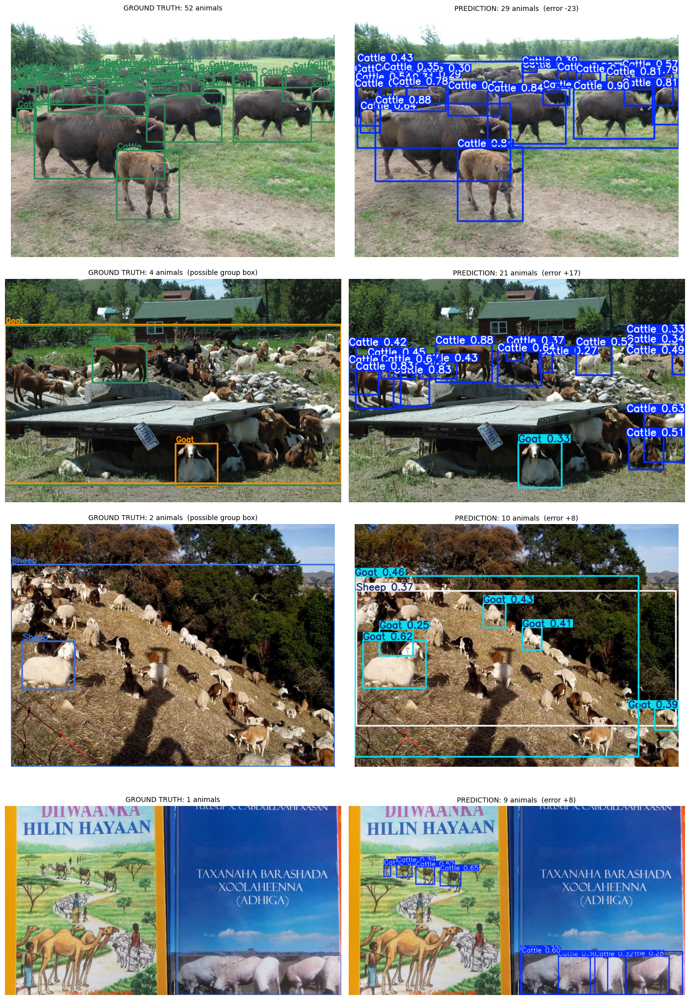

,image,gt_total,pred_total,error,max_box_area,group_flag
151,a508c9f38bd589c5.jpg,52,29,-23,0.123,False
183,ce5b35b756aa7f33.jpg,4,21,17,0.712,True
200,dcd58dbfeef7b6e8.jpg,2,10,8,0.830,True
101,5e230d318b281174.jpg,1,9,8,0.101,False


Images with a possible group box: 80 of 225 (35.6%) but they cause 28.1% of the squared counting error.


In [17]:
# =====================================================================
# D2.  Worst counting failures: ground truth vs prediction side by side
# =====================================================================
worst = dft.sort_values("abs_error", ascending=False).head(4)
fig, axes = plt.subplots(len(worst), 2, figsize=(14, 5.2 * len(worst)))
for (_, r), ax in zip(worst.iterrows(), axes):
    path = DATA_DIR / "images" / "test" / r.image
    boxes, _ = parse_label_file(DATA_DIR / "labels" / "test" / (path.stem + ".txt"))
    ax[0].imshow(rgb(draw_boxes(cv2.imread(str(path)), boxes)))
    ax[0].set_title(f"GROUND TRUTH: {r.gt_total} animals" + ("  (possible group box)" if r.group_flag else ""), fontsize=10)
    pr = model.predict(str(path), conf=CONF_COUNT, iou=IOU_NMS, imgsz=IMGSZ, device=DEVICE, verbose=False)[0]
    ax[1].imshow(rgb(pr.plot())); ax[1].set_title(f"PREDICTION: {r.pred_total} animals  (error {r.error:+d})", fontsize=10)
    ax[0].axis("off"); ax[1].axis("off")
savefig("fig_D_worst_failures.png")
display(worst[["image", "gt_total", "pred_total", "error", "max_box_area", "group_flag"]].round(3))
worst.to_csv(TAB_DIR / "worst_counting_failures.csv", index=False)

# how much of the total squared counting error comes from images with a possible group box?
se = dft.error ** 2
share_group = float(se[dft.group_flag].sum() / se.sum()) if se.sum() > 0 else 0.0
print(f"Images with a possible group box: {int(dft.group_flag.sum())} of {len(dft)} "
      f"({dft.group_flag.mean():.1%}) but they cause {share_group:.1%} of the squared counting error.")
RESULTS["group_img_share"] = float(dft.group_flag.mean()); RESULTS["group_err_share"] = share_group

Confusion, % of each true class (columns of the matrix):


,True class,predicted as Cattle,predicted as Goat,predicted as Sheep,missed (background)
0,Cattle,63.8,2.4,1.9,31.9
1,Goat,12.0,52.0,6.0,30.0
2,Sheep,7.7,5.8,51.9,34.6


,recall,boxes
size,,
small (<1%),0.508,295
medium (1-10%),0.596,287
large (>10%),0.726,248


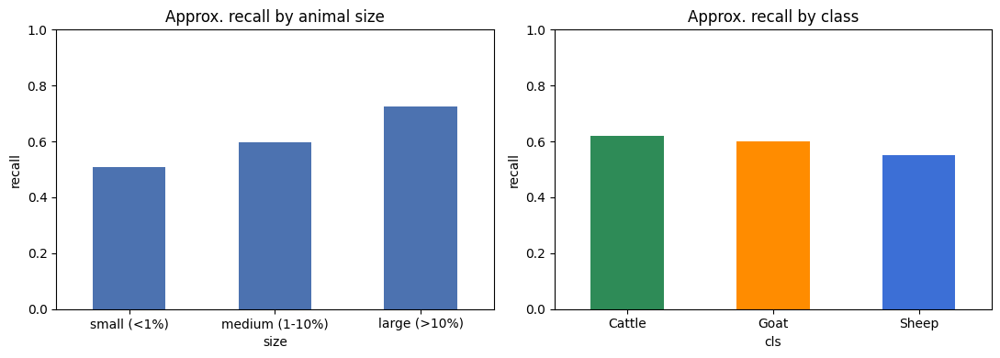

In [18]:
# =====================================================================
# D3.  Class confusion (numbers) + recall by animal size
# =====================================================================
def iou_one_to_many(b, bs):
    x1 = np.maximum(b[0], bs[:, 0]); y1 = np.maximum(b[1], bs[:, 1]); x2 = np.minimum(b[2], bs[:, 2]); y2 = np.minimum(b[3], bs[:, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    return inter / ((b[2] - b[0]) * (b[3] - b[1]) + (bs[:, 2] - bs[:, 0]) * (bs[:, 3] - bs[:, 1]) - inter + 1e-9)

# --- confusion: what happens to each TRUE class ---
conf_rows = []
for j, tc in enumerate(CLASSES):
    col = cm_norm[:, j]
    conf_rows.append({"True class": tc, **{f"predicted as {l}": round(100 * col[i], 1) for i, l in enumerate(CLASSES)},
                      "missed (background)": round(100 * col[len(CLASSES)], 1)})
conf_tab = pd.DataFrame(conf_rows); conf_tab.to_csv(TAB_DIR / "confusion_percent_by_true_class.csv", index=False)
print("Confusion, % of each true class (columns of the matrix):"); display(conf_tab)

# --- approximate recall by box size and class ---
rec_rows = []
for n, p in test_preds.items():
    boxes, _ = parse_label_file(DATA_DIR / "labels" / "test" / (Path(n).stem + ".txt"))
    keep_p = p["conf"] >= CONF_COUNT
    for c, xc, yc, w, h in boxes:
        g = np.array([xc - w / 2, yc - h / 2, xc + w / 2, yc + h / 2])
        sel = keep_p & (p["cls"] == c)
        hit = bool(sel.any() and iou_one_to_many(g, p["xyxyn"][sel]).max() >= 0.5)
        rec_rows.append(dict(cls=CLASSES[c], area=w * h, hit=hit))
rec = pd.DataFrame(rec_rows)
rec["size"] = pd.cut(rec.area, [0, 0.01, 0.10, 1.01], labels=["small (<1%)", "medium (1-10%)", "large (>10%)"])
rec_size = rec.groupby("size", observed=True).hit.agg(["mean", "count"]).rename(columns={"mean": "recall", "count": "boxes"})
rec_cls = rec.groupby("cls").hit.mean().rename("recall")
display(rec_size.round(3)); rec_size.to_csv(TAB_DIR / "recall_by_box_size.csv")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
rec_size.recall.plot.bar(ax=ax[0], rot=0, color="#4c72b0", ylim=(0, 1)); ax[0].set_title("Approx. recall by animal size"); ax[0].set_ylabel("recall")
rec_cls.plot.bar(ax=ax[1], rot=0, color=CLASS_COLORS, ylim=(0, 1)); ax[1].set_title("Approx. recall by class"); ax[1].set_ylabel("recall")
savefig("fig_D_recall_by_size_and_class.png")
RESULTS["rec_size"] = rec_size; RESULTS["conf_tab"] = conf_tab

Predicting val:   0%|          | 0/8 [00:00<?, ?it/s]

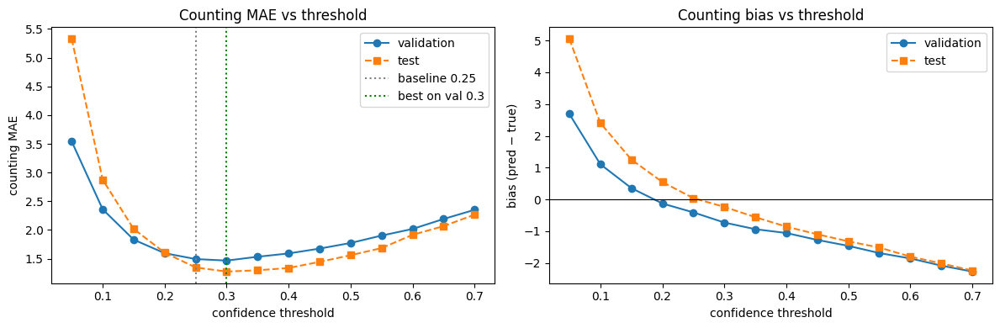

Best threshold on VALIDATION = 0.3. Test MAE: 1.35 at 0.25  ->  1.28 at 0.3


In [19]:
# =====================================================================
# D4.  Confidence-threshold sweep for counting (val -> test)
# =====================================================================
val_preds = predict_split("val")
thrs = np.round(np.arange(0.05, 0.71, 0.05), 2)
sweep = []
for t in thrs:
    dv = counts_at("val", val_preds, t); dt = counts_at("test", test_preds, t)
    sweep.append(dict(threshold=t, val_MAE=dv.abs_error.mean(), val_bias=dv.error.mean(), test_MAE=dt.abs_error.mean(), test_bias=dt.error.mean()))
sweep = pd.DataFrame(sweep); sweep.to_csv(TAB_DIR / "threshold_sweep.csv", index=False)
best_thr = float(sweep.loc[sweep.val_MAE.idxmin(), "threshold"])
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(sweep.threshold, sweep.val_MAE, "o-", label="validation"); ax[0].plot(sweep.threshold, sweep.test_MAE, "s--", label="test")
ax[0].axvline(CONF_COUNT, color="gray", ls=":", label=f"baseline {CONF_COUNT}"); ax[0].axvline(best_thr, color="g", ls=":", label=f"best on val {best_thr}")
ax[0].set_xlabel("confidence threshold"); ax[0].set_ylabel("counting MAE"); ax[0].legend(); ax[0].set_title("Counting MAE vs threshold")
ax[1].plot(sweep.threshold, sweep.val_bias, "o-", label="validation"); ax[1].plot(sweep.threshold, sweep.test_bias, "s--", label="test")
ax[1].axhline(0, color="k", lw=.8); ax[1].set_xlabel("confidence threshold"); ax[1].set_ylabel("bias (pred − true)"); ax[1].legend(); ax[1].set_title("Counting bias vs threshold")
savefig("fig_D_threshold_sweep.png")
t_base = sweep.loc[sweep.threshold == CONF_COUNT, "test_MAE"].iloc[0] if (sweep.threshold == CONF_COUNT).any() else float("nan")
t_best = sweep.loc[sweep.threshold == best_thr, "test_MAE"].iloc[0]
print(f"Best threshold on VALIDATION = {best_thr}. Test MAE: {t_base:.2f} at {CONF_COUNT}  ->  {t_best:.2f} at {best_thr}")
RESULTS["best_thr"] = best_thr; RESULTS["test_mae_base"] = float(t_base); RESULTS["test_mae_best"] = float(t_best)

In [23]:
# =====================================================================
# E2.  Zip the deliverable and show download links
# =====================================================================
# copy the training plots Ultralytics produced (curves, label stats, ...) into the package
tr_dir = OUT_DIR / "training_results"; tr_dir.mkdir(exist_ok=True)
for f in (BEST.parent.parent).glob("*.png"):
    shutil.copy2(f, tr_dir / f.name)
for f in (BEST.parent.parent).glob("*.csv"):
    shutil.copy2(f, tr_dir / f.name)
(OUT_DIR / "weights").mkdir(exist_ok=True); shutil.copy2(BEST, OUT_DIR / "weights" / "best.pt")

def zip_folder(folder, zip_path):
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
        for f in sorted(Path(folder).rglob("*")):
            if f.is_file():
                z.write(f, f.relative_to(folder))
    return zip_path

pkg_zip = zip_folder(OUT_DIR, WORK / "deliverable2_package.zip")
deliver = [pkg_zip]
if ZIP_DATASET:
    deliver.append(zip_folder(DATA_DIR, WORK / "livestock_dataset.zip"))
shutil.copy2(BEST, WORK / "best.pt")                      # weights also at the top level for easy download
deliver.append(WORK / "best.pt"); deliver.append(OUT_DIR / "README.md")

print("FILES TO DOWNLOAD:")
for f in deliver:
    print(f"  {f.name:32s} {f.stat().st_size / 1e6:8.1f} MB   -> {f}")
for f in deliver:
    display(FileLink(os.path.relpath(f, os.getcwd())))
print("\nOn Kaggle: if a link does not work, use Save Version (Save & Run All), then Output tab -> download.")

FILES TO DOWNLOAD:
  deliverable2_package.zip             27.1 MB   -> /kaggle/working/deliverable2_package.zip
  best.pt                               6.5 MB   -> /kaggle/working/best.pt
  README.md                             0.0 MB   -> /kaggle/working/outputs/README.md


/kaggle/working/deliverable2_package.zip

/kaggle/working/best.pt

/kaggle/working/outputs/README.md


On Kaggle: if a link does not work, use Save Version (Save & Run All), then Output tab -> download.
